# 4.4 Теплопроводность: неявная схема

# 4.4 热传导：隐式格式

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 4.3), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})

Matplotlib is building the font cache; this may take a moment.


## Та же задача нагрева
Стержень длиной $0.10$ м, $\alpha=10^{-4}$ м²/с, границы 100 и 20 °C, начальная температура внутри 20 °C.
Неявный Эйлер использует вторую производную на новом временном слое:
$$-\mathrm{Fo}T_{i-1}^{n+1}+(1+2\mathrm{Fo})T_i^{n+1}-\mathrm{Fo}T_{i+1}^{n+1}=T_i^n.$$

## 相同的加热问题
沿用杆长、热扩散率、初温和边界温度。后向欧拉格式在新时间层计算二阶空间导数，每一步需要求解线性方程组。

In [2]:
alpha, L, Nx = 1e-4, 0.10, 51
TL, TR = 100.0, 20.0
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
T_initial = np.full(Nx, 20.0)
T_initial[0], T_initial[-1] = TL, TR

## Матрица и граничные значения
В вектор неизвестных входят только внутренние узлы. Известные температуры границ добавляются в первый и последний элементы правой части. Матрицу строим один раз.

## 矩阵与边界值
未知向量只含内部节点。边界温度分别加入右端向量的首项和末项，矩阵只需构造一次。

In [3]:
def backward_euler(T_initial, Fo, n_steps, TL, TR):
    T = np.asarray(T_initial, dtype=float).copy()
    T[0], T[-1] = TL, TR
    n_int = len(T) - 2
    A = (np.diag((1 + 2*Fo)*np.ones(n_int))
         + np.diag(-Fo*np.ones(n_int-1), 1)
         + np.diag(-Fo*np.ones(n_int-1), -1))
    history = [T.copy()]
    for n in range(n_steps):
        b = T[1:-1].copy()
        b[0] += Fo*TL
        b[-1] += Fo*TR
        T[1:-1] = np.linalg.solve(A, b)
        T[0], T[-1] = TL, TR
        history.append(T.copy())
    return np.array(history)

In [4]:
Fo_implicit = 2.0
dt_implicit = Fo_implicit*dx**2/alpha
implicit_history = backward_euler(
    T_initial, Fo_implicit, 100, TL, TR)
T_implicit = implicit_history[-1]
print(f"dt={dt_implicit:g} с / s; t_end={100*dt_implicit:g} с / s")
print(f"T(L/2, 8 с)={T_implicit[Nx//2]:.6f} °C")
print("Диапазон / 温度范围:", T_implicit.min(), T_implicit.max())

dt=0.08 с / s; t_end=8 с / s
T(L/2, 8 с)=36.823752 °C
Диапазон / 温度范围: 20.0 100.0


## Сравнение при одинаковом времени
Для явной схемы Fo=0.4 и 500 шагов; для неявной Fo=2 и 100 шагов. Оба расчёта заканчиваются в 8 с. Разница между двумя приближениями не равна известной точной ошибке.

## 在相同时刻比较
显式格式 Fo=0.4、500 步；隐式格式 Fo=2、100 步。均终止于 8 s。两种近似解之间的差异并不等于已知的真实误差。

In [5]:
def ftcs(T_initial, Fo, n_steps, TL, TR):
    T = np.asarray(T_initial, dtype=float).copy()
    T[0], T[-1] = TL, TR
    history = [T.copy()]
    for n in range(n_steps):
        T_new = T.copy()
        T_new[1:-1] = (T[1:-1] + Fo *
                      (T[2:] - 2*T[1:-1] + T[:-2]))
        T_new[0], T_new[-1] = TL, TR
        T = T_new
        history.append(T.copy())
    return np.array(history)

max |T_exp − T_imp| = 0.132885 K


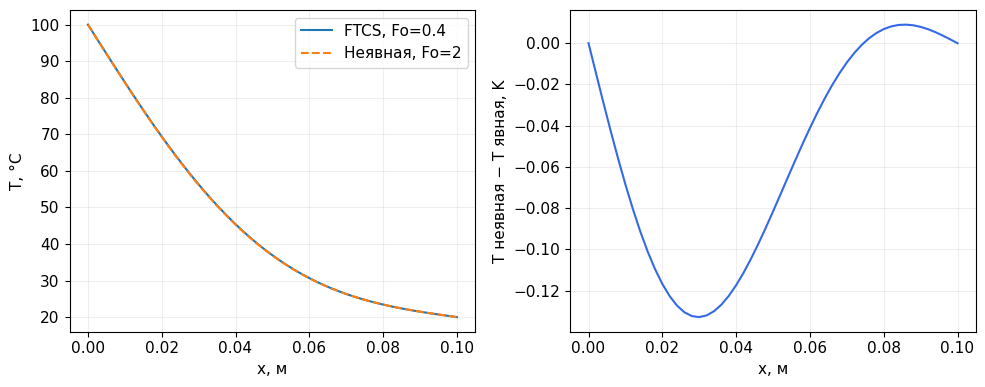

In [6]:
explicit_history = ftcs(T_initial, 0.4, 500, TL, TR)
T_explicit = explicit_history[-1]
profile_difference = np.max(abs(T_explicit-T_implicit))
print(f"max |T_exp − T_imp| = {profile_difference:.6f} K")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(x, T_explicit, label="FTCS, Fo=0.4")
axes[0].plot(x, T_implicit, "--", label="Неявная, Fo=2")
axes[0].set(xlabel="x, м", ylabel="T, °C")
axes[0].legend()
axes[1].plot(x, T_implicit-T_explicit, color="#356AE6")
axes[1].set(xlabel="x, м", ylabel="T неявная − T явная, K")
fig.tight_layout(); plt.show()

## Устойчивость и точность
Неявная схема для этой линейной задачи устойчива при любом положительном шаге, но большой шаг ухудшает точность.
Чтобы измерить именно временную ошибку, используем отдельный синусоидальный тест с границами 20 °C. На фиксированной сетке его **точное по времени решение полудискретной системы** затухает с коэффициентом
$$\lambda_h=\frac{4\alpha}{\Delta x^2}\sin^2\!\frac{\pi}{2(N_x-1)}.$$
Сравнение с ним исключает пространственную погрешность.

## 稳定性与准确性
对于本线性问题，隐式格式在任意正时间步下稳定，但步长过大仍会降低准确性。
为单独测量时间误差，使用两端 20 °C 的正弦测试。在固定空间网格上，半离散系统的精确时间解按上述 $\lambda_h$ 指数衰减。以它为参考可排除空间离散误差。

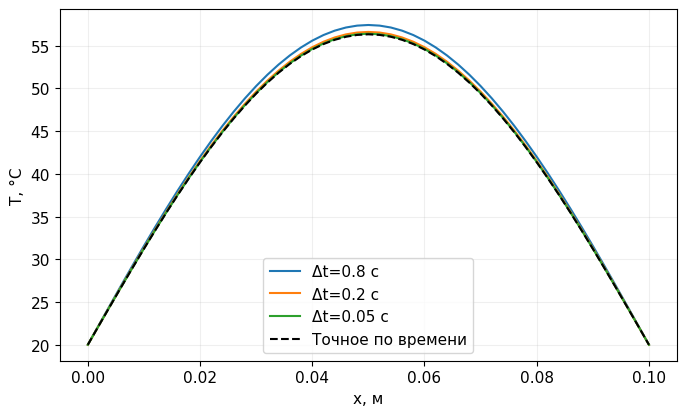

dt=0.8: ошибка / 误差=1.091618e+00 K
dt=0.4: ошибка / 误差=5.556334e-01 K
dt=0.2: ошибка / 误差=2.803527e-01 K
dt=0.1: ошибка / 误差=1.408208e-01 K
dt=0.05: ошибка / 误差=7.057281e-02 K
Порядок / 阶数: [0.9742623  0.98689037 0.99338297 0.99667567]


In [7]:
sine_initial = 20 + 80*np.sin(np.pi*x/L)
lambda_h = 4*alpha/dx**2 * np.sin(np.pi/(2*(Nx-1)))**2
sine_reference = 20 + 80*np.exp(-lambda_h*8)*np.sin(np.pi*x/L)
# Choose steps that end exactly at 8 s. / 选择恰好到达 8 s 的步长。
time_steps = np.array([0.8, 0.4, 0.2, 0.1, 0.05])
time_errors = []
fig, ax = plt.subplots()
for dt_test in time_steps:
    Fo_test = alpha*dt_test/dx**2
    H = backward_euler(sine_initial, Fo_test, round(8/dt_test), 20., 20.)
    time_errors.append(np.max(abs(H[-1]-sine_reference)))
    if dt_test in [0.8, 0.2, 0.05]:
        ax.plot(x, H[-1], label=f"Δt={dt_test:g} с")
ax.plot(x, sine_reference, "k--", label="Точное по времени")
ax.set(xlabel="x, м", ylabel="T, °C")
ax.legend(); fig.tight_layout(); plt.show()
time_errors = np.array(time_errors)
for h, error in zip(time_steps, time_errors):
    print(f"dt={h:g}: ошибка / 误差={error:.6e} K")
print("Порядок / 阶数:", np.log2(time_errors[:-1]/time_errors[1:]))

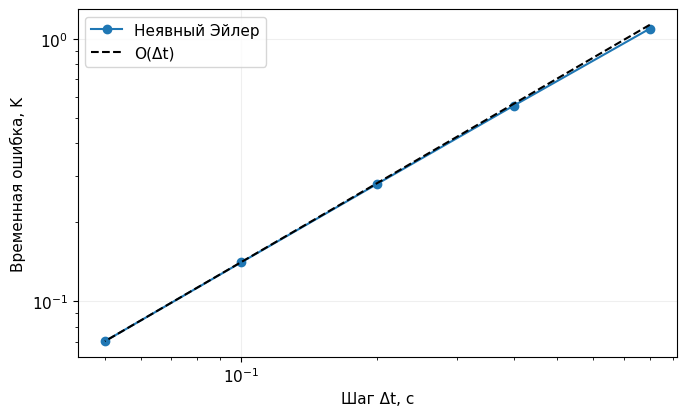

In [8]:
fig, ax = plt.subplots()
ax.loglog(time_steps, time_errors, "o-", label="Неявный Эйлер")
ax.loglog(time_steps, time_errors[-1]*time_steps/time_steps[-1], "k--", label="O(Δt)")
ax.set(xlabel="Шаг Δt, с", ylabel="Временная ошибка, K")
ax.legend(); fig.tight_layout(); plt.show()

## Стационарный предел
При постоянных температурах границ профиль стремится к прямой. В длинном расчёте сравним решение с этим пределом.

## 稳态极限
边界温度固定时，最终温度分布应趋于直线。延长计算时间并与稳态解比较。

In [9]:
steady = TL + (TR-TL)*x/L
long_history = backward_euler(T_initial, 10.0, 500, TL, TR)
steady_error = np.max(abs(long_history[-1]-steady))
print(f"Время / 时间: {500*10*dx**2/alpha:g} с / s")
print(f"Отклонение от стационарного / 稳态偏差: {steady_error:.3e} K")

Время / 时间: 200 с / s
Отклонение от стационарного / 稳态偏差: 2.004e-07 K
